# Prevenção de Evasão Escolar no Ensino Médio Técnico
### Etapa 2 — Pipeline de modelagem: engenharia de atributos, treino e avaliação

**Equipe:** Róbson de Oliveira Cabral · Sidnário Oliveira Rosa · Lucca Queiroz · Lissa Ferreira Massuda · Nathália Vieira Kamimura

Este notebook continua de onde a Etapa 1 (`01_exploracao_dataset.ipynb`) parou. Decisões tomadas com o grupo antes de montar este pipeline:

- **Desbalanceamento de classes:** `class_weight="balanced"` nos dois modelos (sem gerar dados sintéticos).
- **Atributos:** conjunto curado, só os ligados aos três fatores do projeto — desempenho acadêmico, proxy de frequência e indicador socioeconômico.
- **Indicador socioeconômico:** score ponderado — inadimplente = peso 3, mensalidade não em dia = peso 2, não-bolsista = peso 1 (pesos escolhidos pelo grupo a partir do que a exploração mostrou).
- **Critério de escolha do modelo:** recall da classe Risco Alto — não deixar passar alunos de alto risco é mais importante do que evitar falsos alarmes.


## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, recall_score, f1_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

ORDEM_RISCO = ["Risco Alto", "Risco Médio", "Risco Baixo"]
CORES_RISCO = {"Risco Alto": "#B5533C", "Risco Médio": "#C98A3D", "Risco Baixo": "#3F7554"}


## 2. Carregando o dataset processado na Etapa 1

In [2]:
df = pd.read_csv("../dados/processado/dataset_explorado.csv")
print(f"{df.shape[0]} alunos, {df.shape[1]} colunas")
df[["risco", "taxa_aprovacao_1sem", "taxa_aprovacao_2sem", "Debtor", "Tuition fees up to date", "Scholarship holder"]].head()


4424 alunos, 40 colunas


,risco,taxa_aprovacao_1sem,taxa_aprovacao_2sem,Debtor,Tuition fees up to date,Scholarship holder
0,Risco Alto,NaN,NaN,0,1,0
1,Risco Baixo,1.000000,1.000000,0,0,0
2,Risco Alto,0.000000,0.000000,0,0,0
3,Risco Baixo,1.000000,0.833333,0,1,0
4,Risco Baixo,0.833333,1.000000,0,1,0


## 3. Engenharia de atributos final

### 3.1 Indicador socioeconômico ponderado

Score = 3 × inadimplente + 2 × (mensalidade NÃO em dia) + 1 × (NÃO é bolsista). Quanto maior, pior a situação socioeconômica do aluno.

In [3]:
df["indicador_socioeconomico"] = (
    3 * df["Debtor"]
    + 2 * (1 - df["Tuition fees up to date"])
    + 1 * (1 - df["Scholarship holder"])
)

print("Faixa do indicador:", df["indicador_socioeconomico"].min(), "a", df["indicador_socioeconomico"].max())
df.groupby("risco")["indicador_socioeconomico"].mean().reindex(ORDEM_RISCO).round(2)


Faixa do indicador: 0 a 6


risco
Risco Alto     2.21
Risco Médio    1.28
Risco Baixo    0.79
Name: indicador_socioeconomico, dtype: float64

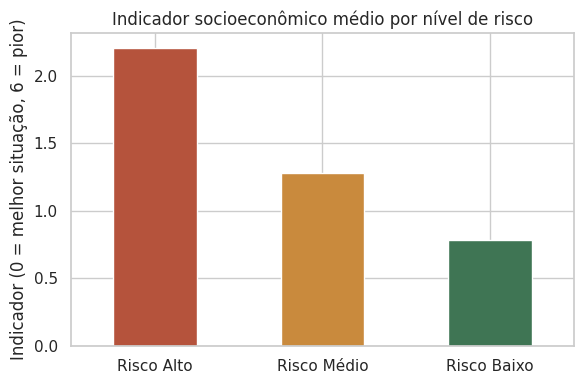

In [4]:
plt.figure(figsize=(6, 4))
medias = df.groupby("risco")["indicador_socioeconomico"].mean().reindex(ORDEM_RISCO)
medias.plot(kind="bar", color=[CORES_RISCO[c] for c in ORDEM_RISCO])
plt.title("Indicador socioeconômico médio por nível de risco")
plt.ylabel("Indicador (0 = melhor situação, 6 = pior)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


O indicador cresce do Risco Baixo para o Risco Alto, como esperado — confirma que a ponderação escolhida faz sentido com os dados reais.

### 3.2 Conjunto curado de atributos

Seis atributos, ligados aos três fatores do projeto (desempenho acadêmico, proxy de frequência e indicador socioeconômico):

Alguns alunos não têm nenhuma unidade curricular matriculada em um semestre (divisão 0/0 na taxa de aprovação, que vira ausente). Nesses casos, preenchemos a taxa de aprovação com 0 — tratando como o cenário mais conservador (pior caso), já que não há evidência de aprovação nenhuma.

In [5]:
ATRIBUTOS = [
    "Admission grade",                     # desempenho acadêmico prévio (nota de admissão)
    "Curricular units 1st sem (grade)",    # desempenho no 1º semestre
    "Curricular units 2nd sem (grade)",    # desempenho no 2º semestre
    "taxa_aprovacao_1sem",                 # proxy de frequência/engajamento, 1º semestre
    "taxa_aprovacao_2sem",                 # proxy de frequência/engajamento, 2º semestre
    "indicador_socioeconomico",            # fator socioeconômico
]

df[ATRIBUTOS] = df[ATRIBUTOS].fillna(0)

X = df[ATRIBUTOS]
y = df["risco"]

print(f"Atributos usados no modelo: {ATRIBUTOS}")
X.describe().round(2)


Atributos usados no modelo: ['Admission grade', 'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)', 'taxa_aprovacao_1sem', 'taxa_aprovacao_2sem', 'indicador_socioeconomico']


,Admission grade,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),taxa_aprovacao_1sem,taxa_aprovacao_2sem,indicador_socioeconomico
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,126.98,10.64,10.23,0.70,0.66,1.33
std,14.48,4.84,5.21,0.37,0.38,1.47
min,95.00,0.00,0.00,0.00,0.00,0.00
25%,117.90,11.00,10.75,0.50,0.40,1.00
50%,126.10,12.29,12.20,0.83,0.83,1.00
75%,134.80,13.40,13.33,1.00,1.00,1.00
max,190.00,18.88,18.57,1.00,1.00,6.00


## 4. Separação treino/teste

Split estratificado 80/20, preservando a proporção das três classes de risco.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} alunos | Teste: {X_test.shape[0]} alunos")
print("\nProporção de classes no treino:")
print((y_train.value_counts(normalize=True).reindex(ORDEM_RISCO) * 100).round(1))
print("\nProporção de classes no teste:")
print((y_test.value_counts(normalize=True).reindex(ORDEM_RISCO) * 100).round(1))


Treino: 3539 alunos | Teste: 885 alunos

Proporção de classes no treino:
risco
Risco Alto     32.1
Risco Médio    17.9
Risco Baixo    49.9
Name: proportion, dtype: float64

Proporção de classes no teste:
risco
Risco Alto     32.1
Risco Médio    18.0
Risco Baixo    49.9
Name: proportion, dtype: float64


## 5. Treinando os dois modelos

Os dois usam `class_weight="balanced"` para compensar o desbalanceamento das classes. A Regressão Logística é sensível à escala dos atributos, então normalizamos com `StandardScaler` dentro de um `Pipeline` — a Árvore de Decisão não precisa disso, mas usar o mesmo pipeline simplifica o código.

In [7]:
modelos = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    ]),
    "Árvore de Decisão": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", DecisionTreeClassifier(class_weight="balanced", max_depth=5, random_state=42)),
    ]),
}

for nome, pipeline in modelos.items():
    pipeline.fit(X_train, y_train)
    print(f"{nome}: treinado.")


Regressão Logística: treinado.
Árvore de Decisão: treinado.


## 6. Avaliação por classe de risco

Para cada modelo: relatório de precisão/recall/F1 por classe e matriz de confusão.

In [8]:
resultados = {}

for nome, pipeline in modelos.items():
    y_pred = pipeline.predict(X_test)
    resultados[nome] = y_pred

    print(f"\n{'=' * 60}\n{nome}\n{'=' * 60}")
    print(classification_report(y_test, y_pred, labels=ORDEM_RISCO, digits=2))



Regressão Logística
              precision    recall  f1-score   support

  Risco Alto       0.78      0.66      0.71       284
 Risco Médio       0.34      0.44      0.38       159
 Risco Baixo       0.82      0.81      0.81       442

    accuracy                           0.70       885
   macro avg       0.65      0.64      0.64       885
weighted avg       0.72      0.70      0.71       885


Árvore de Decisão
              precision    recall  f1-score   support

  Risco Alto       0.80      0.61      0.69       284
 Risco Médio       0.35      0.55      0.43       159
 Risco Baixo       0.84      0.80      0.82       442

    accuracy                           0.70       885
   macro avg       0.67      0.65      0.65       885
weighted avg       0.74      0.70      0.71       885



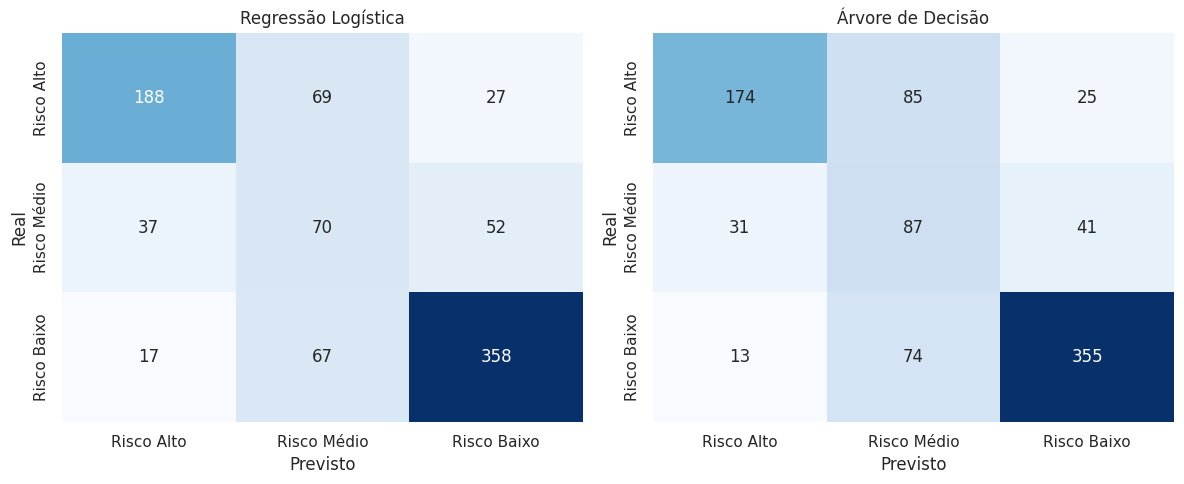

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nome, y_pred) in zip(axes, resultados.items()):
    cm = confusion_matrix(y_test, y_pred, labels=ORDEM_RISCO)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=ORDEM_RISCO, yticklabels=ORDEM_RISCO, ax=ax,
    )
    ax.set_title(nome)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")

plt.tight_layout()
plt.show()


## 7. Comparando os modelos pelo critério combinado

Critério de escolha: **recall da classe Risco Alto** — o modelo que identifica a maior proporção de alunos realmente em alto risco.

In [10]:
comparacao = []
for nome, y_pred in resultados.items():
    recall_alto = recall_score(y_test, y_pred, labels=["Risco Alto"], average="macro")
    f1_macro = f1_score(y_test, y_pred, labels=ORDEM_RISCO, average="macro")
    comparacao.append({"modelo": nome, "recall_risco_alto": round(recall_alto, 3), "f1_macro": round(f1_macro, 3)})

comparacao_df = pd.DataFrame(comparacao).set_index("modelo")
comparacao_df


,recall_risco_alto,f1_macro
modelo,,
Regressão Logística,0.662,0.638
Árvore de Decisão,0.613,0.649


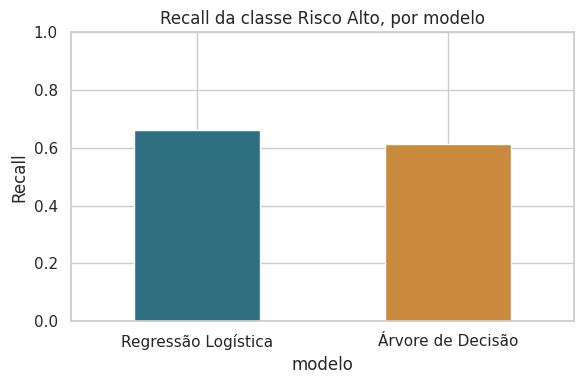

Modelo escolhido (maior recall em Risco Alto): Regressão Logística


In [11]:
plt.figure(figsize=(6, 4))
comparacao_df["recall_risco_alto"].plot(kind="bar", color=["#2F6F82", "#C98A3D"])
plt.title("Recall da classe Risco Alto, por modelo")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

modelo_vencedor_nome = comparacao_df["recall_risco_alto"].idxmax()
print(f"Modelo escolhido (maior recall em Risco Alto): {modelo_vencedor_nome}")


## 8. Exportando o modelo vencedor

Salvamos o pipeline completo (normalização + classificador) e a lista de atributos usados, para o dashboard Streamlit carregar na próxima etapa.

In [12]:
modelo_vencedor = modelos[modelo_vencedor_nome]

os.makedirs("../modelo", exist_ok=True)
joblib.dump(modelo_vencedor, "../modelo/modelo_risco.pkl")

with open("../modelo/features.json", "w", encoding="utf-8") as f:
    json.dump({
        "modelo": modelo_vencedor_nome,
        "atributos": ATRIBUTOS,
        "classes": ORDEM_RISCO,
        "recall_risco_alto_teste": float(comparacao_df.loc[modelo_vencedor_nome, "recall_risco_alto"]),
        "f1_macro_teste": float(comparacao_df.loc[modelo_vencedor_nome, "f1_macro"]),
    }, f, ensure_ascii=False, indent=2)

print(f"Modelo salvo em modelo/modelo_risco.pkl")
print(f"Metadados salvos em modelo/features.json")


Modelo salvo em modelo/modelo_risco.pkl
Metadados salvos em modelo/features.json


## 9. Próximos passos

Esta etapa cobriu a engenharia de atributos final, o treino dos dois modelos interpretáveis e a escolha do modelo vencedor pelo recall da classe Risco Alto. Os próximos passos (ver Cronograma do Projeto) são:

1. Construir o dashboard em Streamlit, consumindo `modelo/modelo_risco.pkl` e `modelo/features.json`.
2. Montar as quatro telas já planejadas: visão geral, lista priorizada, ficha do aluno e upload de dados.
3. Fazer o deploy no Streamlit Community Cloud.
4. Redigir o relatório técnico com os fatores de risco mapeados aqui.
